# Symbolic calculation

This notebook contains the exercises of the symbolic calculation lecture part 3.

In [1]:
import sympy as sym
import math
from typing import List

x,t,n,c = sym.symbols("x t n c")

# Polynomial sequence and code

## Exercise 3.1

We will study the sequence $B_n$ of Bernoulli polynomials.
By definition, this sequence is defined by:

$$
\begin{align*}
  B_0(x) &= 1 \\
  \frac{B_{n+1}(x)} {dx} &= (n+1)B_n(x) \ (1) \\
  \forall n > 0, \int _{0}^{1} B_n(x)dx &= 0 \ (2) \\
\end{align*}
$$

We will try to calculate $B_1$ by applying the following processus:
* Use (1) for obtaining the derivative $P$ of $B_1$.
* Calculate an antiderivative of P and add a constant c to it for producing E.
* Use (2) to obtain an equation on E.
* Calculate c by solving the previous system and deduce the value of $B_1$ by substituting the solution in E 

In [2]:
B0 = 1
n = 0
P = (n+1) * B0
P

1

In [3]:
E=sym.integrate(P,x)+c
E

c + x

In [4]:
eq = sym.integrate(E,(x,0,1))
cSol = sym.solve(eq,c)[0]
B1 = E.subs({c:cSol})
B1

x - 1/2

* Calculate $B_2$ the same way.

In [5]:
n = 1
P = (n+1) * B1
E=sym.integrate(P,x)+c
eq = sym.integrate(E,(x,0,1))
cSol = sym.solve(eq,c)[0]
B2 = E.subs({c:cSol})
B2

x**2 - x + 1/6

* Code a function that calculates the first 20 Bernoulli polynomials and put them in a list.

In [6]:
B = sym.Integer(1)
Bs = [(1,B)]
for n in range(20):
    P = (n+1) * B
    E=sym.integrate(P,x)+c
    eq = sym.integrate(E,(x,0,1))
    cSol = sym.solve(eq,c)[0]
    B = E.subs({c:cSol})
    Bs.append((n+1,B))
Bs

[(1, 1),
 (1, x - 1/2),
 (2, x**2 - x + 1/6),
 (3, x**3 - 3*x**2/2 + x/2),
 (4, x**4 - 2*x**3 + x**2 - 1/30),
 (5, x**5 - 5*x**4/2 + 5*x**3/3 - x/6),
 (6, x**6 - 3*x**5 + 5*x**4/2 - x**2/2 + 1/42),
 (7, x**7 - 7*x**6/2 + 7*x**5/2 - 7*x**3/6 + x/6),
 (8, x**8 - 4*x**7 + 14*x**6/3 - 7*x**4/3 + 2*x**2/3 - 1/30),
 (9, x**9 - 9*x**8/2 + 6*x**7 - 21*x**5/5 + 2*x**3 - 3*x/10),
 (10, x**10 - 5*x**9 + 15*x**8/2 - 7*x**6 + 5*x**4 - 3*x**2/2 + 5/66),
 (11, x**11 - 11*x**10/2 + 55*x**9/6 - 11*x**7 + 11*x**5 - 11*x**3/2 + 5*x/6),
 (12,
  x**12 - 6*x**11 + 11*x**10 - 33*x**8/2 + 22*x**6 - 33*x**4/2 + 5*x**2 - 691/2730),
 (13,
  x**13 - 13*x**12/2 + 13*x**11 - 143*x**9/6 + 286*x**7/7 - 429*x**5/10 + 65*x**3/3 - 691*x/210),
 (14,
  x**14 - 7*x**13 + 91*x**12/6 - 1001*x**10/30 + 143*x**8/2 - 1001*x**6/10 + 455*x**4/6 - 691*x**2/30 + 7/6),
 (15,
  x**15 - 15*x**14/2 + 35*x**13/2 - 91*x**11/2 + 715*x**9/6 - 429*x**7/2 + 455*x**5/2 - 691*x**3/6 + 35*x/2),
 (16,
  x**16 - 8*x**15 + 20*x**14 - 182*x**12/3 +

Bernoulli's numbers are defined as: $b_0 = B_0(0)$
* Calculate the first $b_n$ from the previous list of polynomials.

In [7]:
bns = [ (ix, B.subs(x,0) ) for (ix,B) in Bs]
bns

[(1, 1),
 (1, -1/2),
 (2, 1/6),
 (3, 0),
 (4, -1/30),
 (5, 0),
 (6, 1/42),
 (7, 0),
 (8, -1/30),
 (9, 0),
 (10, 5/66),
 (11, 0),
 (12, -691/2730),
 (13, 0),
 (14, 7/6),
 (15, 0),
 (16, -3617/510),
 (17, 0),
 (18, 43867/798),
 (19, 0),
 (20, -174611/330)]

In [8]:
# Differential equation

## Exercise 3.2

## Simple oscillator

In this exercise, we will declare the following ODP and make SymPy solve it. 

$-kx(t) = m \frac{d^2}{dt^2} x(t)$

* Declare the different constant, variables and function that figure in this ODP

In [9]:
k, m = sym.symbols ("k m", positive = True)
t = sym.Symbol( "t", real=True)
x = sym.Function ("x", real=True)

* Declare the ODE
* Solve the ODE

In [10]:
eq = sym.Eq(-k * x(t), m * sym.diff(x(t),t,t))
eq

Eq(-k*x(t), m*Derivative(x(t), (t, 2)))

In [11]:
sol = sym.dsolve(eq, x(t))
sol

Eq(x(t), C1*sin(sqrt(k)*t/sqrt(m)) + C2*cos(sqrt(k)*t/sqrt(m)))

* Given the following condition at t=0
  * $x(0) = L$
  * $\frac{dx(0)}{dt}=0$
* Solve the ODP by adding the initial conditions.

In [12]:
L = sym.symbols("L", positive = True)
ics = {x(0):L , x(t).diff(t).subs(t,0): 0}
sol2 = sym.dsolve(eq, x(t), ics = ics)
sol2

Eq(x(t), L*cos(sqrt(k)*t/sqrt(m)))

* What solutions do you find when constants are not declared as positive reals?

In [13]:
k, m, L = sym.symbols ("k m L")
t = sym.Symbol( "t")
x = sym.Function ("x")
eq = sym.Eq(-k * x(t), m * sym.diff(x(t),t,t))

ics = {x(0):L , x(t).diff(t).subs(t,0): 0}
sol3 = sym.dsolve(eq, x(t), ics = ics)
sol3

Eq(x(t), L*exp(t*sqrt(-k/m))/2 + L*exp(-t*sqrt(-k/m))/2)

# Laplace transformation for ODE

## Exercise 3.3

We will experiment Laplace transform applied to simple functions:
* $f_1(t) = e^{at}$
* $w \in \mathbb{R}, f_2(t) = \sin(wt)$

In [14]:
t,s = sym.symbols("t s")
a,w = sym.symbols("a w", real=True)
Y1_s = sym.laplace_transform( sym.exp(a*t), t, s )
Y1_s

(1/(-a + s), a, True)

In [15]:
Y2_s = sym.laplace_transform( sym.sin(w*t), t, s )
Y2_s

(w/(s**2 + w**2), 0, True)

Calculate the Laplace transform of:
* $n \in \mathbb{N}, f_3(t) = t^n$
* $f_4(t) = f_3'(t)$

In [16]:
n = sym.symbols("n", integer=True)
Y3_s = sym.laplace_transform( t**n, t, s )
Y3_s

(gamma(n + 1)/(s*s**n), 0, n > -1)

In [17]:
Y4_s = sym.laplace_transform( sym.diff(t**n,t), t, s )
Y4_s

(n*s**(1 - n)*gamma(n)/s, 0, n > 0)

## Exercise 3.4

We will use Laplace transform for resolving an ODE.

Consider the following ODE: $y''(t) + 3y(t) - \cos(2t) = 0 $
With initial condition $y(0) = 0, y'(0)=1$

* Declare the required symbols
* Declare the ODE
* Apply the Laplace transform to the ODE and keep first element of the result in eq_laplace

In [18]:
y = sym.Function("y")
t,s = sym.symbols("t s")
eq =  sym.diff(y(t),t,t) + 3 * y(t) - sym.cos(2*t) 
eq

3*y(t) - cos(2*t) + Derivative(y(t), (t, 2))

In [19]:
eq_laplace = sym.laplace_transform(eq, t , s)[0]
eq_laplace

s**2*LaplaceTransform(y(t), t, s) - s*y(0) - s/(s**2 + 4) + 3*LaplaceTransform(y(t), t, s) - Subs(Derivative(y(t), t), t, 0)

* Substitute the Y(s) in eq_laplace to "Y(s)" (Hint: L_y = sym.laplace_transform(y(t),t,s)[0] )
* Resolve the last equation by applying solve function on "Y(s)". Keep the first solution only.

In [20]:
L_y = sym.laplace_transform(y(t),t,s)[0]
eq_laplace_2 = eq_laplace.subs( L_y, "Y(s)")
eq_laplace_2

s**2*Y(s) - s*y(0) - s/(s**2 + 4) + 3*Y(s) - Subs(Derivative(y(t), t), t, 0)

In [21]:
Y_s = sym.solve(eq_laplace_2, "Y(s)")[0]
Y_s

(s**3*y(0) + s**2*Subs(Derivative(y(t), t), t, 0) + 4*s*y(0) + s + 4*Subs(Derivative(y(t), t), t, 0))/(s**4 + 7*s**2 + 12)

* Apply the Laplace inverse transform to obtain the solution of the ODE.
* Substitute the initial conditions to this solution (Hint: the derivative condition is represented by the term sym.Subs(sym.Derivative(y(t), t), t, 0))
* Observe that the $\theta$ function represents the Heaviside step function

In [22]:
y_t = sym.inverse_laplace_transform(Y_s,s,t)
y_t

((y(0) + 1)*cos(sqrt(3)*t) + sqrt(3)*sin(sqrt(3)*t)*Subs(Derivative(y(t), t), t, 0)/3)*Heaviside(t) - cos(2*t)*Heaviside(t)

In [23]:
y_t.subs({y(0):0, sym.Subs(sym.Derivative(y(t), t), t, 0):1} )

(sqrt(3)*sin(sqrt(3)*t)/3 + cos(sqrt(3)*t))*Heaviside(t) - cos(2*t)*Heaviside(t)

# Fourier Transform

## Exercise 3.5

We will practice the calculation of Fourier series on a periodic function or period T
* Declare symbols for a periodic (period T) real function f(t)=t 
* Calculate its fourier series s between $[-\frac{T}{2},\frac{T}{2}]$

In [24]:
t = sym.symbols( "t", real = True)
T = sym.symbols("T", positive = True )
f_t = t

In [25]:
s = sym.fourier_series(f_t, (t, -T/2, T/2))
s

FourierSeries(t, (t, -T/2, T/2), (0, SeqFormula(0, (_k, 1, oo)), SeqFormula(2*Piecewise((-T**2*cos(_n*pi)/(2*_n*pi) + T**2*sin(_n*pi)/(2*_n**2*pi**2), (_n > -oo) & (_n < oo) & Ne(_n, 0)), (0, True))*sin(2*_n*pi*t/T)/T, (_n, 1, oo))))

* Calculate spi series by setting T to $\pi$ in s.

In [26]:
spi = s.subs(T, sym.pi)
spi

FourierSeries(t, (t, -pi/2, pi/2), (0, SeqFormula(0, (_k, 1, oo)), SeqFormula(2*Piecewise((-pi*cos(_n*pi)/(2*_n) + sin(_n*pi)/(2*_n**2), (_n > -oo) & (_n < oo) & Ne(_n, 0)), (0, True))*sin(2*_n*t)/pi, (_n, 1, oo))))

* Truncate the previous series up to 3, 5 and 7 and assign the results to $s_1,s_2,s_3$
* Use the SymPy plot function to represent $f, s_1, s_2, s_3$ between $[-\frac{T}{2},\frac{T}{2}]$ (Hint: plot( f1,f2,.., (t, a, b ) )) where a,b are the x limits of the plot)
* Conclude about the partial Fourier series precision

In [27]:
s1 = spi.truncate(n=3)
s2 = spi.truncate(n=5)
s3 = spi.truncate(n=7)
s3

sin(2*t) - sin(4*t)/2 + sin(6*t)/3 - sin(8*t)/4 + sin(10*t)/5 - sin(12*t)/6 + sin(14*t)/7

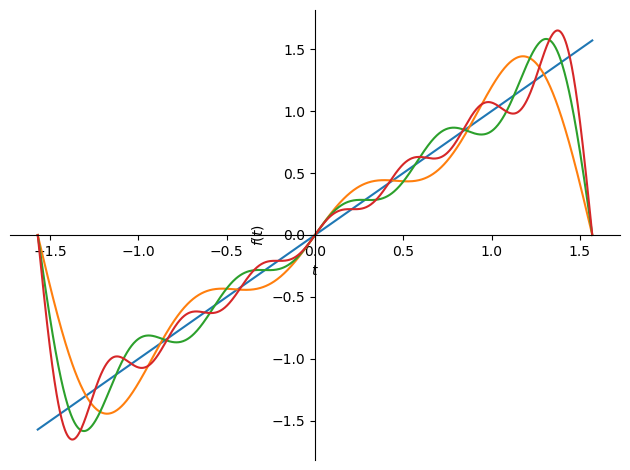

In [28]:
sym.plot(f_t, s1, s2, s3,(t,-sym.pi/2, sym.pi/2))

## Exercise 3.6

We now experiment with extended Fourier transform.

* Import the complex symbols x,k from the SymPy.abc package
* Calculate the Fourier transform of the $e^{-x^2}$ as $F_k$

In [29]:
from sympy.abc import x,k

F_k = sym.fourier_transform(sym.exp(-x**2), x, k)
F_k

sqrt(pi)*exp(-pi**2*k**2)

* Calculate the inverse Fourier transform of the previous frequency function

In [30]:
f_x = sym.inverse_fourier_transform( F_k, k , x)
f_x

exp(-x**2)

* Calculate the frequency function $G_k = F_{k+p}$ where p is an integer symbol.

In [31]:
p = sym.symbols("p", integer = True)
G_k = F_k.subs( k, k+p )
G_k

sqrt(pi)*exp(-pi**2*(k + p)**2)

* Calculate the corresponding inverse function of $G_k$
* Conclude by comparing f(x) and g(x)

In [32]:
g_x = sym.inverse_fourier_transform( G_k, k , x)
g_x

exp(-x*(2*I*pi*p + x))

## Exercise 3.7

We will experiment with heat PDE in SymPy.
Given thermal diffusivity a and the length of the bar L both positive real, the heat diffusion model is:

$$
\begin{align*}
  \frac{\partial u(t,x)} {\partial t} &= a  \frac{\partial^2 u(t,x)}{\partial x^2}  \ (1) \\
  U(0,x) &= f(x) \ (2) \\
  U(t,0) &= 0 \ (3) \\
  U(t,L) &= 0 \ (4) \\
\end{align*}
$$

A known solution of this problem is given by:

$$
\begin{align*}
  U_s(t,x) &= \sum \limits _{n=1} ^{\infty} F_n \sin ( \frac{n \pi x} {L} ) e^{ - \frac{n^2 \pi^2} {L^2} at} \\
  F_n &= \frac{2} {L} \int _{0} ^{L} f(y)  \sin ( \frac{n \pi y} {L} ) dy \\
\end{align*}
$$

The objective is to verify that the equations (1) ... (4) are verified by $u_s$.

* Declare the needed symbols with their correct type constraints (Hint: a function f is needed)
* Declare symbolically $F_n, u_s$ (Hint: use the summation function)


In [33]:
a, L, x, y = sym.symbols("a L x y", real=True, positive=True)
n = sym.symbols("n", integer=True, positive=True)
u = sym.Function("u", real=True)
f = sym.Function("f", real=True)

In [34]:
Fn = 2/L* sym.integrate( f(y)*sym.sin(n*sym.pi*y/L), (y,0,L))
Fn

2*Integral(f(y)*sin(pi*n*y/L), (y, 0, L))/L

In [35]:
us = sym.summation( Fn*sym.sin(n*sym.pi*x/L)*sym.exp(-(n**2 * sym.pi**2 / L**2 )*a*t), (n,1,sym.oo) )
us

Sum(2*exp(-pi**2*a*n**2*t/L**2)*sin(pi*n*x/L)*Integral(f(y)*sin(pi*n*y/L), (y, 0, L))/L, (n, 1, oo))

* Check that $u_s$ satisfies the PDE (1)             

In [36]:
eq1 = sym.Eq( us.diff( t), a*us.diff(x,x) )
eq1.simplify()

True

* Do you manage to prove with SymPy that the initial condition (1) is satisfied by $u_s$ by keeping the generic function f?
* Is it possible to prove it with the particular function $f(y) = y(L-y)$
* Conclude about the limitation of SymPy

In [37]:
eq2 = sym.Eq( us.subs(t,0), f(x) )
eq2.simplify()

Eq(f(x), 2*Sum(sin(pi*n*x/L)*Integral(f(y)*sin(pi*n*y/L), (y, 0, L)), (n, 1, oo))/L)

In [38]:
eq2_1 = sym.Eq( us.subs( {t:0, f(y):y*(L-y), L:1} ),  y*(L-y) )
eq2_1

Eq(Sum(2*sin(pi*n*x)*Integral(y*(1 - y)*sin(pi*n*y), (y, 0, 1)), (n, 1, oo)), y*(L - y))

* Verify that (3) and (4) are satisfied by $u_s$

In [39]:
us.subs(x,0).simplify()

0

In [40]:
us.subs(x,L).simplify()

0

Instead of considering an infinite series for $u_s$, we will use a limited expandment $ulim_s$ keeping the 20 first terms.

We suppose that the bar has a length of 1 meter and is made of metal with diffusivity coefficient equal to $10^{-3}$ with an initial difference of temperature between its middle and the edge of 10 degrees.

* Calculate $ulim_s$ with $L=1, a=10^{-3}, f(y)=40y(1-y)$.

In [41]:
b_s = sym.summation( Fn*sym.sin(n*sym.pi*x/L)*sym.exp(-(n**2 * sym.pi**2 / L**2 )*a*t), (n,1,20) )
ulim_s = b_s.subs({L:1,a:1E-3, f(y):40*y*(1-y)}).simplify().expand()
ulim_s

320*exp(-0.361*pi**2*t)*sin(19*pi*x)/(6859*pi**3) + 320*exp(-0.289*pi**2*t)*sin(17*pi*x)/(4913*pi**3) + 64*exp(-0.225*pi**2*t)*sin(15*pi*x)/(675*pi**3) + 320*exp(-0.169*pi**2*t)*sin(13*pi*x)/(2197*pi**3) + 320*exp(-0.121*pi**2*t)*sin(11*pi*x)/(1331*pi**3) + 320*exp(-0.0809999999999995*pi**2*t)*sin(9*pi*x)/(729*pi**3) + 320*exp(-0.0489999999999995*pi**2*t)*sin(7*pi*x)/(343*pi**3) + 64*exp(-0.0249999999999995*pi**2*t)*sin(5*pi*x)/(25*pi**3) + 320*exp(-0.00899999999999945*pi**2*t)*sin(3*pi*x)/(27*pi**3) + 320*exp(-0.000999999999999446*pi**2*t)*sin(pi*x)/pi**3

* Represent the difference between $ulim_s(0,x)$ and $f(x)=40x(1-x)$
* Conclude about the satisfaction of (1)

In [42]:
d_x = ulim_s.subs(t,0) - 40*x*(1-x)
d_x

-40*x*(1 - x) + 320*sin(pi*x)/pi**3 + 320*sin(3*pi*x)/(27*pi**3) + 64*sin(5*pi*x)/(25*pi**3) + 320*sin(7*pi*x)/(343*pi**3) + 320*sin(9*pi*x)/(729*pi**3) + 320*sin(11*pi*x)/(1331*pi**3) + 320*sin(13*pi*x)/(2197*pi**3) + 64*sin(15*pi*x)/(675*pi**3) + 320*sin(17*pi*x)/(4913*pi**3) + 320*sin(19*pi*x)/(6859*pi**3)

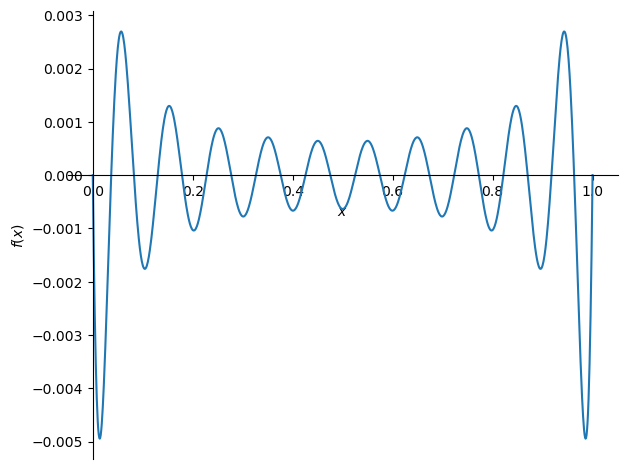

In [43]:
sym.plot(d_x,(x,0,1))

* Represent with plot3d the evolution of the temperature of the bar between 0 and 100 seconds

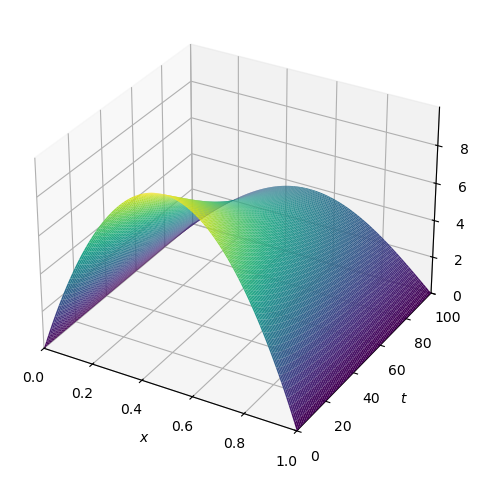

In [44]:
sym.plotting.plot3d(ulim_s, (x,0,1), (t,0,100))

## 3.8 Exercise 

## Chemical Kinetics

This exercise comes from the SymPy documentation and shows an example of ODE numerical resolution with SciPy solve_ivp function.

The nonlinear ODEs take the following form where $y_0,y_1,y_2$ are 3 different concentrations of chemical species (https://www.SymPy.org/scipy-2017-codegen-tutorial/notebooks/25-chemical-kinetics-intro.html):

$r_f = k_f y_0(t)^2 y_1(t)$

$r_b = k_b y_3(t)^2$

$\frac{dy_0(t)} {dt} = 2(r_b-r_f)$

$\frac{dy_1(t)} {dt} = r_b-r_f$

$\frac{dy_2(t)} {dt} =  2(r_f-r_b)$

$\vec{y}(t) = \begin{bmatrix} y_{0}(t) \\ y_{1}(t) \\ y_{2}(t) \\ \end{bmatrix}$

$ \frac{d\vec{y}(t)} {dt} = h( \vec{y}(t) ) $ (given the previous ODEs)

The objective of this exercise is to provide SciPy function solve_ivp with a function $f$ that, given $t,\vec{y}(t),k_f,k_b$ returns $\frac{d\vec{y}(t)} {dt}= h( \vec{y}(t) )$. solve_ivp is then able to calculate a numerical approximation for the ODEs with the time between 0 and 10 seconds.

* Import numpy as np, scipy as sp and matplotlib.pyplot as plt
* Declare the required symbols (hint: sym.symbols("y:3") for declaring the array y)

In [45]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

In [46]:
y = sym.symbols('y:3')
kf, kb = sym.symbols('kf kb')
t = sym.symbols("t")

* Declare the variables $r_f,r_b$

In [47]:
rf = kf * y[0]**2 * y[1]
rb = kb * y[2]**2

* Declare $ \frac{d\vec{y}(t)} {dt}$ in the ydot variable

In [48]:
ydot = [2*(rb - rf), rb - rf, 2*(rf - rb)]
ydot

[2*kb*y2**2 - 2*kf*y0**2*y1,
 kb*y2**2 - kf*y0**2*y1,
 -2*kb*y2**2 + 2*kf*y0**2*y1]

* Declare the f variable depending on the input variables (t,y,kf,kb) and the expression ydot (as its implementation)

In [49]:
f = sym.lambdify((t, y, kf, kb), ydot)

* Declare an array ks of constants set to 0.47 and 0.17
* Declare the initial concentration y0 set to 1, 1 and 0

In [50]:
ks = [0.42, 0.17]
y0 = [1,1,0]

* Declare an array ts of discretized time using numpy function linspace between 0 and 10 for 50 points

In [51]:
ts = np.linspace(0,10,50)

* Invoke the scipy.integrate.solve_ivp by providing as input the f function, the interval (0,10) of integration, the initial concentrations y0, the time array ts (hint: t_eval=ts) and the constants ks ((hint: args=ks)). Set the solution variable with the returned value.

In [52]:
solution = sp.integrate.solve_ivp(f, (0, 10), y0, t_eval=ts, args=ks)
solution.y

array([[1.        , 0.8588458 , 0.76037109, 0.68865638, 0.63448858,
        0.59298188, 0.56070716, 0.53512394, 0.51478622, 0.49863364,
        0.48571594, 0.47520885, 0.4666383 , 0.45971742, 0.45416064,
        0.44968802, 0.44602514, 0.4429604 , 0.44043698, 0.4383935 ,
        0.43676122, 0.43546445, 0.43442049, 0.43353967, 0.43277066,
        0.43212494, 0.43159916, 0.43118497, 0.43086892, 0.43063257,
        0.43045243, 0.43029995, 0.43014456, 0.42999498, 0.42986356,
        0.42975504, 0.42967192, 0.42961451, 0.42958085, 0.42956676,
        0.42956583, 0.42956944, 0.42956671, 0.42954545, 0.42951959,
        0.4294984 , 0.42948121, 0.42946735, 0.42945611, 0.4294468 ],
       [1.        , 0.9294229 , 0.88018554, 0.84432819, 0.81724429,
        0.79649094, 0.78035358, 0.76756197, 0.75739311, 0.74931682,
        0.74285797, 0.73760443, 0.73331915, 0.72985871, 0.72708032,
        0.72484401, 0.72301257, 0.7214802 , 0.72021849, 0.71919675,
        0.71838061, 0.71773223, 0.71721025, 0.7

* Import matplotlib.pyplot package
* Call plot function with ts and solution.y.T as arguments

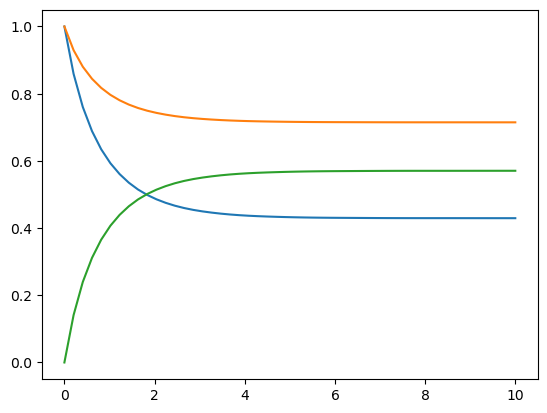

In [53]:
plt.plot(ts, solution.y.T)

* Calculate the jacobian of f by transforming the vector ydot as a Matrix and then calling the jacobian function
* Conclude

In [54]:
sym.Matrix(ydot).jacobian(y)

Matrix([
[-4*kf*y0*y1, -2*kf*y0**2,  4*kb*y2],
[-2*kf*y0*y1,   -kf*y0**2,  2*kb*y2],
[ 4*kf*y0*y1,  2*kf*y0**2, -4*kb*y2]])

* Show that $y_0 + y_2$ is a constant over time
* Show that $2 * y_1 + y_2$ is a constant over time
* How do you explain those results?

In [55]:
invar1 = ydot[0] +  ydot[2]
invar1

0

In [56]:
invar2 = 2 * ydot[1] +  ydot[2]
invar2

0